# LeNet-5 sobre MNIST: arquitectura, kernels y la red vista por dentro

LeNet-5 (LeCun, Bottou, Bengio y Haffner, 1998) es la red convolucional que fijó el patrón que siguen casi todas las redes de visión posteriores: convoluciones que extraen rasgos locales, submuestreo que reduce la resolución y capas totalmente conectadas que deciden la clase.

En este cuaderno vamos a:

1. Leer la arquitectura capa por capa en un diagrama isométrico, donde los **pesos** (kernels y matrices) se distinguen de las **activaciones** (mapas de rasgos).
2. Calcular a mano el tamaño de cada tensor y el número de parámetros.
3. Entender la operación de convolución con un ejemplo numérico, compararla con PyTorch y ver qué hace un kernel sobre un dígito.
4. Entrenar LeNet-5 en la GPU de platypy (RTX 3070) sobre MNIST.
5. Mirar los kernels aprendidos y recorrer la red "capas adentro" con un dígito concreto.
6. Inferir un conjunto de ejemplos de prueba, revisar la matriz de confusión y los errores.

El cuaderno se genera con `scripts/build_lenet_notebook.py`; si quieres cambiar una celda, cambia el script y regenera.

In [1]:
import json
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import DataLoader, random_split
from torchvision import datasets, transforms
from IPython.display import SVG, display

SEED = 42
torch.manual_seed(SEED)
np.random.seed(SEED)
torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")


def find_repo_root(start=None):
    p = Path(start or Path.cwd()).resolve()
    for parent in [p, *p.parents]:
        if (parent / "scripts" / "build_lenet_notebook.py").exists() or (parent / "pyproject.toml").exists():
            return parent
    for c in ["/workspace/friendly-fiesta", "/workspace"]:
        if (Path(c) / "notebooks").exists():
            return Path(c)
    return p


ROOT = find_repo_root()
DATA = ROOT / "data" / "mnist"
OUT_DIR = ROOT / "results" / "lenet"
FIG_DIR = ROOT / "figures" / "lenet"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 10, "axes.labelsize": 9})

print("ROOT   =", ROOT)
print("torch  =", torch.__version__)
print("device =", DEVICE, "|", torch.cuda.get_device_name(0) if DEVICE.type == "cuda" else "CPU")

ROOT   = /workspace/friendly-fiesta
torch  = 2.2.1
device = cuda | NVIDIA GeForce RTX 3070 Laptop GPU


## 1. La arquitectura como una máquina

El diagrama siguiente dibuja LeNet-5 como un banco de trabajo. El flujo va de atrás a adelante: la tarjeta del fondo es la imagen de entrada y los indicadores del frente son las diez clases.

**Lectura del diagrama**

- **Tarjetas grises verticales en rieles ranurados**: son las **activaciones** (mapas de rasgos). Su tamaño es proporcional a la resolución espacial del mapa ($32\to28\to14\to10\to5$) y cada una lleva grabado el mapa real que produjo la red entrenada para el dígito de ejemplo.
- **Sellos ámbar sobre las tarjetas de C1 y C3**: son los **pesos** convolucionales. Cada tarjeta de C1 lleva encima el sello de $5\times5\times1$ que la produjo, y cada tarjeta de C3 un sello de $5\times5\times6$ (seis láminas apiladas, una por canal de entrada de S2). Sobre la cara superior de cada sello está grabado el kernel aprendido (en C3, la lámina del canal 5): ámbar para pesos positivos y azul para negativos. Observa lo pequeños que son frente a las tarjetas: con 25 o 150 pesos se produce un mapa completo, porque el mismo kernel se reutiliza en todas las posiciones.
- **Placas ámbar planas** antes de F5, F6 y la salida: las matrices de las capas totalmente conectadas ($400\times120$, $120\times84$ y $84\times10$). Su tamaño crece con el número de parámetros (la de F5 es con mucho la mayor) y su retícula muestra los pesos promediados por bloques: cada fila es un grupo de neuronas de salida y cada columna un grupo de entradas.
- **Rejillas perforadas grises** entre C1 y S2 y entre C3 y S4: el submuestreo (max pooling $2\times2$). No tiene pesos, por eso no lleva color.
- **Hileras de pernos** F5 (120) y F6 (84): cada perno es una neurona y su altura es su activación.
- **Diez indicadores** al frente: la salida softmax. El único resaltado es la clase que predijo la red.

Los números grabados en el diagrama salen del mismo modelo que se entrena más abajo: el script `scripts/anatomy_lenet/build.mjs` lee `figures/lenet/anatomy_data.json`, que este cuaderno exporta al final.

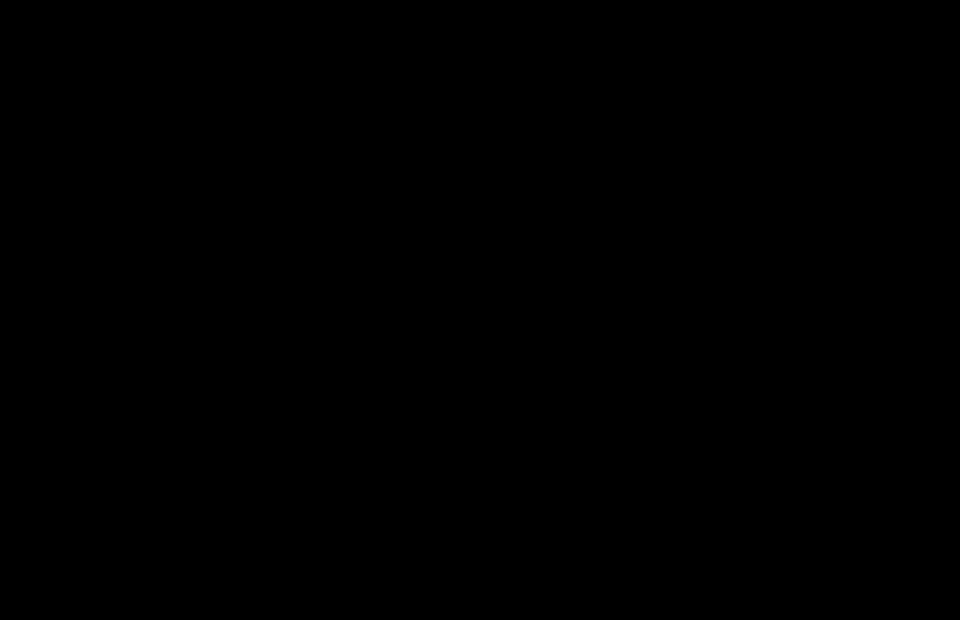

In [2]:
svg_path = FIG_DIR / "lenet_anatomy.svg"
if svg_path.exists():
    display(SVG(filename=str(svg_path)))
else:
    print("Aún no existe", svg_path, "; ejecuta el cuaderno completo y luego scripts/anatomy_lenet/build.mjs")

## 2. Tamaños y parámetros capa por capa

Para una convolución con entrada de lado $W$, kernel de lado $K$, relleno (padding) $P$ y paso (stride) $S$, el lado de la salida es

$$W_{\text{out}} = \left\lfloor \frac{W - K + 2P}{S} \right\rfloor + 1 .$$

LeNet-5 recibe imágenes de $32\times32$. MNIST trae dígitos de $28\times28$, así que les añadimos un marco de 2 píxeles en negro: el dígito queda centrado y los kernels de la primera capa pueden "ver" los trazos que tocan el borde.

| Capa | Operación | Salida | Parámetros |
|---|---|---|---|
| Entrada | imagen en escala de grises | $1\times32\times32$ | 0 |
| C1 | conv $5\times5$, 6 filtros, $S=1$, $P=0$, ReLU | $6\times28\times28$ | $6\cdot(5\cdot5\cdot1)+6 = 156$ |
| S2 | max pooling $2\times2$, $S=2$ | $6\times14\times14$ | 0 |
| C3 | conv $5\times5$, 16 filtros sobre 6 canales, ReLU | $16\times10\times10$ | $16\cdot(5\cdot5\cdot6)+16 = 2\,416$ |
| S4 | max pooling $2\times2$, $S=2$ | $16\times5\times5$ | 0 |
| F5 | aplanado $400\to120$, ReLU | $120$ | $400\cdot120+120 = 48\,120$ |
| F6 | $120\to84$, ReLU | $84$ | $120\cdot84+84 = 10\,164$ |
| Salida | $84\to10$, softmax | $10$ | $84\cdot10+10 = 850$ |
| **Total** | | | **61 706** |

Dos observaciones que conviene subrayar en clase:

- **Las convoluciones tienen muy pocos pesos.** C1 y C3 juntas suman 2 572 parámetros (4 % del total) y, sin embargo, hacen casi todo el trabajo de extraer rasgos. La razón es el **peso compartido**: el mismo kernel de $5\times5$ se aplica en las $28\times28=784$ posiciones de la imagen.
- **F5 concentra el 78 % de los parámetros.** Es la capa que conecta "todo con todo". Por eso las redes modernas reemplazan estas capas por *global average pooling*.

### Diferencias con el LeNet-5 original

El artículo de 1998 usaba tangente hiperbólica escalada, un submuestreo con un coeficiente y un sesgo entrenables por mapa, una tabla de conexiones parciales entre S2 y C3 (cada mapa de C3 veía solo algunos mapas de S2) y una salida con funciones de base radial. Aquí usamos la versión que se enseña hoy: ReLU, max pooling sin parámetros, C3 conectada a los 6 canales y softmax con entropía cruzada. La geometría (tamaños de kernels y de mapas) es idéntica.

In [3]:
def out_side(w, k, p=0, s=1):
    return (w - k + 2 * p) // s + 1


side = 32
tabla = []
side = out_side(side, 5); tabla.append(("C1", 6, side))
side = out_side(side, 2, s=2); tabla.append(("S2", 6, side))
side = out_side(side, 5); tabla.append(("C3", 16, side))
side = out_side(side, 2, s=2); tabla.append(("S4", 16, side))
for nombre, canales, lado in tabla:
    print(f"{nombre}: {canales:>2} x {lado:>2} x {lado:>2}  ->  {canales * lado * lado:>5} activaciones")
print("Vector aplanado que entra a F5:", 16 * 5 * 5)

C1:  6 x 28 x 28  ->   4704 activaciones
S2:  6 x 14 x 14  ->   1176 activaciones
C3: 16 x 10 x 10  ->   1600 activaciones
S4: 16 x  5 x  5  ->    400 activaciones
Vector aplanado que entra a F5: 400


## 3. La operación de convolución

### Definición

En una red convolucional, "convolución" significa en realidad **correlación cruzada** (no se voltea el kernel). Para una entrada $X$ de un canal y un kernel $K$ de $k\times k$ con sesgo $b$, el valor de la salida en la posición $(i,j)$ es

$$Y_{i,j} = b + \sum_{u=0}^{k-1}\sum_{v=0}^{k-1} K_{u,v}\, X_{i+u,\; j+v}.$$

Es un producto punto entre el kernel y el parche de la imagen que tiene debajo. El kernel se desliza por toda la imagen y cada posición produce un número. El resultado es un **mapa de rasgos**: dice *dónde* aparece el patrón que el kernel codifica.

Con $C$ canales de entrada (lo que ocurre en C3, que recibe los 6 mapas de S2), el kernel es un bloque de $C\times k\times k$ y la suma recorre también los canales:

$$Y_{i,j} = b + \sum_{c=0}^{C-1}\sum_{u=0}^{k-1}\sum_{v=0}^{k-1} K_{c,u,v}\, X_{c,\; i+u,\; j+v}.$$

Por eso en el diagrama los sellos de C3 son bloques de seis láminas: un kernel de C3 mira simultáneamente los seis mapas de S2 y produce **un** solo mapa.

### Ejemplo numérico a mano

Tomamos una imagen de $6\times6$ con un borde vertical (columnas izquierdas oscuras, derechas claras) y un kernel de $3\times3$ que detecta bordes verticales.

In [4]:
X = np.array([
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
    [0, 0, 0, 1, 1, 1],
], dtype=np.float32)

K = np.array([
    [-1, 0, 1],
    [-1, 0, 1],
    [-1, 0, 1],
], dtype=np.float32)


def conv2d_manual(x, k, b=0.0):
    kh, kw = k.shape
    H, W = x.shape
    y = np.zeros((H - kh + 1, W - kw + 1), dtype=np.float32)
    for i in range(y.shape[0]):
        for j in range(y.shape[1]):
            parche = x[i:i + kh, j:j + kw]
            y[i, j] = b + np.sum(parche * k)
    return y


Y_manual = conv2d_manual(X, K)
print("Salida manual (4 x 4):")
print(Y_manual)

Y_torch = F.conv2d(torch.from_numpy(X)[None, None], torch.from_numpy(K)[None, None]).squeeze().numpy()
print("\n¿Coincide con F.conv2d de PyTorch?", np.allclose(Y_manual, Y_torch))

Salida manual (4 x 4):
[[0. 3. 3. 0.]
 [0. 3. 3. 0.]
 [0. 3. 3. 0.]
 [0. 3. 3. 0.]]

¿Coincide con F.conv2d de PyTorch? True


La salida vale 3 justo donde el kernel queda montado sobre el borde (columnas 1 y 2 de la salida) y 0 en las zonas planas. Tomemos la posición $(0,1)$: el parche es

$$\begin{pmatrix}0&0&1\\0&0&1\\0&0&1\end{pmatrix},\qquad \sum K\odot\text{parche} = (-1)(0)\cdot3 + (0)(0)\cdot3 + (1)(1)\cdot3 = 3.$$

La figura muestra el recorrido del kernel: el recuadro rojo es el parche que produce la celda resaltada de la salida.

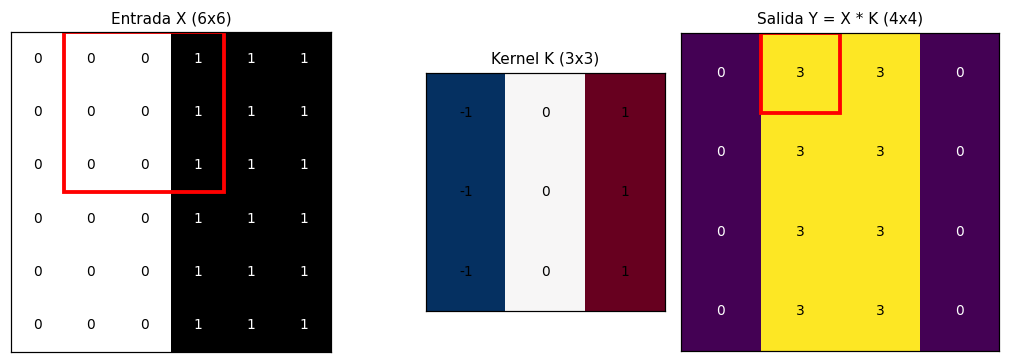

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(10, 3.4), gridspec_kw={"width_ratios": [6, 3, 4]})
for ax, M, titulo in zip(axes, [X, K, Y_manual], ["Entrada X (6x6)", "Kernel K (3x3)", "Salida Y = X * K (4x4)"]):
    ax.imshow(M, cmap="RdBu_r" if M is K else "gray_r" if M is X else "viridis",
              vmin=-1 if M is K else None, vmax=1 if M is K else None)
    for (r, c), v in np.ndenumerate(M):
        ax.text(c, r, f"{v:g}", ha="center", va="center", fontsize=9,
                color="white" if (M is Y_manual and v < 1.5) or (M is X and v > 0.5) else "black")
    ax.set_title(titulo)
    ax.set_xticks([]); ax.set_yticks([])
axes[0].add_patch(plt.Rectangle((0.5, -0.5), 3, 3, fill=False, ec="red", lw=2.5))
axes[2].add_patch(plt.Rectangle((0.5, -0.5), 1, 1, fill=False, ec="red", lw=2.5))
plt.tight_layout()
plt.show()

### Padding, stride y campo receptivo

- **Padding** ($P$): añade un marco de ceros para que el kernel también se centre sobre los píxeles del borde. Con $K=5$ y $P=2$ la salida conserva el tamaño de la entrada. LeNet-5 no usa padding en las capas convolucionales; en su lugar el marco se pone una sola vez en la imagen ($28\to32$).
- **Stride** ($S$): cuántos píxeles avanza el kernel en cada paso. Con $S=2$ la salida se reduce a la mitad.
- **Campo receptivo**: la región de la imagen original de la que depende una neurona. Una neurona de C1 ve $5\times5$ píxeles. Una de S2 ve $6\times6$. Una de C3 ve $14\times14$ y una de S4 ve $16\times16$, es decir, la mitad del lado de la imagen. Al apilar capas, cada neurona integra información de una zona cada vez mayor; por eso las capas profundas responden a formas completas (curvas, cruces, cierres) y las primeras a trazos cortos.

La recursión es $r_\ell = r_{\ell-1} + (k_\ell - 1)\, j_{\ell-1}$, donde $j$ es el salto acumulado (producto de los strides anteriores).

In [6]:
capas = [("C1", 5, 1), ("S2", 2, 2), ("C3", 5, 1), ("S4", 2, 2)]
r, j = 1, 1
for nombre, k, s in capas:
    r = r + (k - 1) * j
    j = j * s
    print(f"{nombre}: campo receptivo {r:>2} x {r:<2}  (salto acumulado {j})")

C1: campo receptivo  5 x 5   (salto acumulado 1)
S2: campo receptivo  6 x 6   (salto acumulado 2)
C3: campo receptivo 14 x 14  (salto acumulado 2)
S4: campo receptivo 16 x 16  (salto acumulado 4)


### Pooling

El **max pooling** $2\times2$ con paso 2 toma cada bloque de $2\times2$ y se queda con el máximo. Reduce el lado a la mitad, no tiene pesos y aporta una pequeña invariancia a traslaciones: si el trazo se mueve un píxel dentro del bloque, el máximo no cambia.

In [7]:
A = np.array([[1, 3, 2, 0],
              [4, 6, 1, 1],
              [0, 2, 9, 5],
              [1, 1, 3, 7]], dtype=np.float32)
P_max = F.max_pool2d(torch.from_numpy(A)[None, None], 2).squeeze().numpy()
print("Entrada 4x4:\n", A)
print("Max pooling 2x2 -> 2x2:\n", P_max)

Entrada 4x4:
 [[1. 3. 2. 0.]
 [4. 6. 1. 1.]
 [0. 2. 9. 5.]
 [1. 1. 3. 7.]]
Max pooling 2x2 -> 2x2:
 [[6. 2.]
 [2. 9.]]


## 4. Los datos: MNIST

MNIST contiene 70 000 dígitos manuscritos de $28\times28$ en escala de grises: 60 000 de entrenamiento y 10 000 de prueba. Separamos 5 000 imágenes del entrenamiento como validación para vigilar el sobreajuste sin tocar el conjunto de prueba.

Transformaciones:

1. `Pad(2)`: de $28\times28$ a $32\times32$, el tamaño de entrada de LeNet-5.
2. `ToTensor()`: píxeles en $[0,1]$.
3. `Normalize(0.1307, 0.3081)`: media y desviación estándar de MNIST, para que la entrada quede centrada en cero.

In [8]:
MEAN, STD = 0.1307, 0.3081
tfm = transforms.Compose([
    transforms.Pad(2),
    transforms.ToTensor(),
    transforms.Normalize((MEAN,), (STD,)),
])

descargar = not (DATA / "MNIST" / "raw" / "t10k-labels-idx1-ubyte").exists()
train_full = datasets.MNIST(DATA, train=True, download=descargar, transform=tfm)
test_set = datasets.MNIST(DATA, train=False, download=descargar, transform=tfm)

train_set, val_set = random_split(train_full, [55_000, 5_000], generator=torch.Generator().manual_seed(SEED))

BATCH = 128
train_loader = DataLoader(train_set, batch_size=BATCH, shuffle=True, num_workers=2, pin_memory=True,
                          generator=torch.Generator().manual_seed(SEED))
val_loader = DataLoader(val_set, batch_size=1000, shuffle=False, num_workers=2, pin_memory=True)
test_loader = DataLoader(test_set, batch_size=1000, shuffle=False, num_workers=2, pin_memory=True)

print(f"entrenamiento: {len(train_set)}  validación: {len(val_set)}  prueba: {len(test_set)}")
x0, y0 = train_full[0]
print("forma de una imagen:", tuple(x0.shape), "| etiqueta:", y0)

entrenamiento: 55000  validación: 5000  prueba: 10000
forma de una imagen: (1, 32, 32) | etiqueta: 5


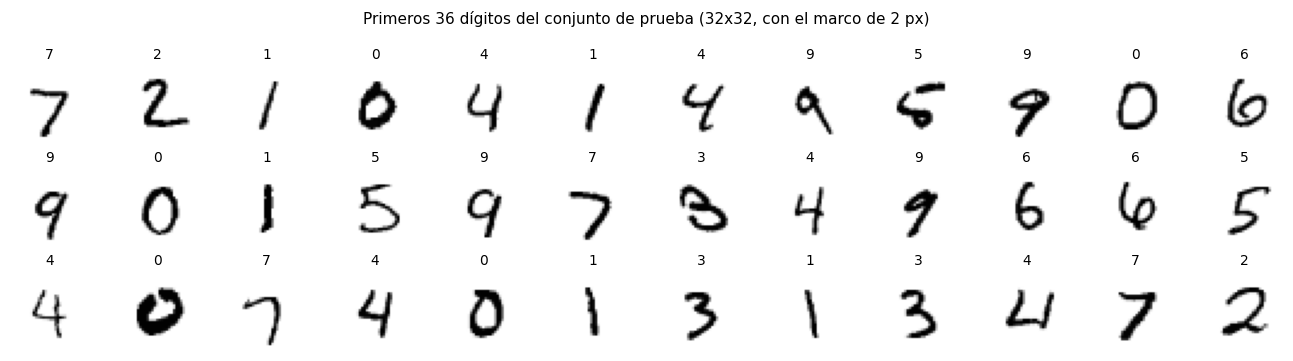

Ejemplos por clase en entrenamiento: [5923, 6742, 5958, 6131, 5842, 5421, 5918, 6265, 5851, 5949]


In [9]:
def to_img(x):
    return (x.squeeze().cpu().numpy() * STD + MEAN)


fig, axes = plt.subplots(3, 12, figsize=(12, 3.3))
for ax, idx in zip(axes.flat, range(36)):
    x, y = test_set[idx]
    ax.imshow(to_img(x), cmap="gray_r")
    ax.set_title(str(y), fontsize=9)
    ax.axis("off")
fig.suptitle("Primeros 36 dígitos del conjunto de prueba (32x32, con el marco de 2 px)", fontsize=10)
plt.tight_layout()
plt.show()

conteo = torch.bincount(train_full.targets, minlength=10)
print("Ejemplos por clase en entrenamiento:", conteo.tolist())

## 5. El modelo en PyTorch

La clase guarda las activaciones intermedias en un diccionario cuando se le pide (`keep=True`). Las usaremos para recorrer la red por dentro.

In [10]:
class LeNet5(nn.Module):
    def __init__(self):
        super().__init__()
        self.c1 = nn.Conv2d(1, 6, kernel_size=5)      # 32 -> 28
        self.s2 = nn.MaxPool2d(2)                     # 28 -> 14
        self.c3 = nn.Conv2d(6, 16, kernel_size=5)     # 14 -> 10
        self.s4 = nn.MaxPool2d(2)                     # 10 -> 5
        self.f5 = nn.Linear(16 * 5 * 5, 120)
        self.f6 = nn.Linear(120, 84)
        self.out = nn.Linear(84, 10)

    def forward(self, x, keep=False):
        acts = {"input": x}
        x = F.relu(self.c1(x)); acts["c1"] = x
        x = self.s2(x);         acts["s2"] = x
        x = F.relu(self.c3(x)); acts["c3"] = x
        x = self.s4(x);         acts["s4"] = x
        x = torch.flatten(x, 1)
        x = F.relu(self.f5(x)); acts["f5"] = x
        x = F.relu(self.f6(x)); acts["f6"] = x
        logits = self.out(x);   acts["logits"] = logits
        return (logits, acts) if keep else logits


model = LeNet5().to(DEVICE)
print(model)
print()
total = 0
for nombre, p in model.named_parameters():
    total += p.numel()
    print(f"{nombre:<12} {str(tuple(p.shape)):<18} {p.numel():>7}")
print(f"{'TOTAL':<31} {total:>7}")

LeNet5(
  (c1): Conv2d(1, 6, kernel_size=(5, 5), stride=(1, 1))
  (s2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (c3): Conv2d(6, 16, kernel_size=(5, 5), stride=(1, 1))
  (s4): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (f5): Linear(in_features=400, out_features=120, bias=True)
  (f6): Linear(in_features=120, out_features=84, bias=True)
  (out): Linear(in_features=84, out_features=10, bias=True)
)

c1.weight    (6, 1, 5, 5)           150
c1.bias      (6,)                     6
c3.weight    (16, 6, 5, 5)         2400
c3.bias      (16,)                   16
f5.weight    (120, 400)           48000
f5.bias      (120,)                 120
f6.weight    (84, 120)            10080
f6.bias      (84,)                   84
out.weight   (10, 84)               840
out.bias     (10,)                   10
TOTAL                             61706


In [11]:
with torch.no_grad():
    _, acts = model(torch.zeros(1, 1, 32, 32, device=DEVICE), keep=True)
for k, v in acts.items():
    print(f"{k:<7} {tuple(v.shape)}")

input   (1, 1, 32, 32)
c1      (1, 6, 28, 28)
s2      (1, 6, 14, 14)
c3      (1, 16, 10, 10)
s4      (1, 16, 5, 5)
f5      (1, 120)
f6      (1, 84)
logits  (1, 10)


## 6. Entrenamiento en la GPU

- Pérdida: entropía cruzada sobre los logits, $\mathcal{L} = -\log \operatorname{softmax}(z)_{y}$.
- Optimizador: Adam con $\eta = 10^{-3}$ y un decaimiento coseno de la tasa de aprendizaje a lo largo de las épocas.
- 12 épocas, lotes de 128.

Antes de entrenar guardamos una copia de los kernels de C1 tal como los dejó la inicialización aleatoria; después los compararemos con los aprendidos.

In [12]:
c1_inicial = model.c1.weight.detach().cpu().clone()

EPOCHS = 12
optimizer = torch.optim.Adam(model.parameters(), lr=1e-3)
scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(optimizer, T_max=EPOCHS)
criterion = nn.CrossEntropyLoss()


def evaluate(loader):
    model.eval()
    loss_sum, correct, n = 0.0, 0, 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
            logits = model(x)
            loss_sum += criterion(logits, y).item() * y.size(0)
            correct += (logits.argmax(1) == y).sum().item()
            n += y.size(0)
    return loss_sum / n, correct / n


history = {"train_loss": [], "train_acc": [], "val_loss": [], "val_acc": []}
t0 = time.perf_counter()
for epoch in range(1, EPOCHS + 1):
    model.train()
    loss_sum, correct, n = 0.0, 0, 0
    for x, y in train_loader:
        x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)
        logits = model(x)
        loss = criterion(logits, y)
        loss.backward()
        optimizer.step()
        loss_sum += loss.item() * y.size(0)
        correct += (logits.argmax(1) == y).sum().item()
        n += y.size(0)
    scheduler.step()
    val_loss, val_acc = evaluate(val_loader)
    history["train_loss"].append(loss_sum / n); history["train_acc"].append(correct / n)
    history["val_loss"].append(val_loss); history["val_acc"].append(val_acc)
    print(f"época {epoch:>2}/{EPOCHS}  pérdida {loss_sum / n:.4f}  exactitud {correct / n:.4f}  "
          f"| validación: pérdida {val_loss:.4f}  exactitud {val_acc:.4f}")
train_time = time.perf_counter() - t0
print(f"\nTiempo de entrenamiento: {train_time:.1f} s en {DEVICE}")

época  1/12  pérdida 0.3184  exactitud 0.9064  | validación: pérdida 0.1075  exactitud 0.9692


época  2/12  pérdida 0.0819  exactitud 0.9751  | validación: pérdida 0.0752  exactitud 0.9762


época  3/12  pérdida 0.0571  exactitud 0.9817  | validación: pérdida 0.0653  exactitud 0.9804


época  4/12  pérdida 0.0441  exactitud 0.9857  | validación: pérdida 0.0533  exactitud 0.9842


época  5/12  pérdida 0.0339  exactitud 0.9888  | validación: pérdida 0.0472  exactitud 0.9848


época  6/12  pérdida 0.0271  exactitud 0.9911  | validación: pérdida 0.0439  exactitud 0.9864


... (2 outputs left out)

época  9/12  pérdida 0.0126  exactitud 0.9963  | validación: pérdida 0.0397  exactitud 0.9880


época 10/12  pérdida 0.0100  exactitud 0.9972  | validación: pérdida 0.0380  exactitud 0.9884


época 11/12  pérdida 0.0080  exactitud 0.9981  | validación: pérdida 0.0376  exactitud 0.9876


época 12/12  pérdida 0.0069  exactitud 0.9984  | validación: pérdida 0.0378  exactitud 0.9886

Tiempo de entrenamiento: 41.6 s en cuda


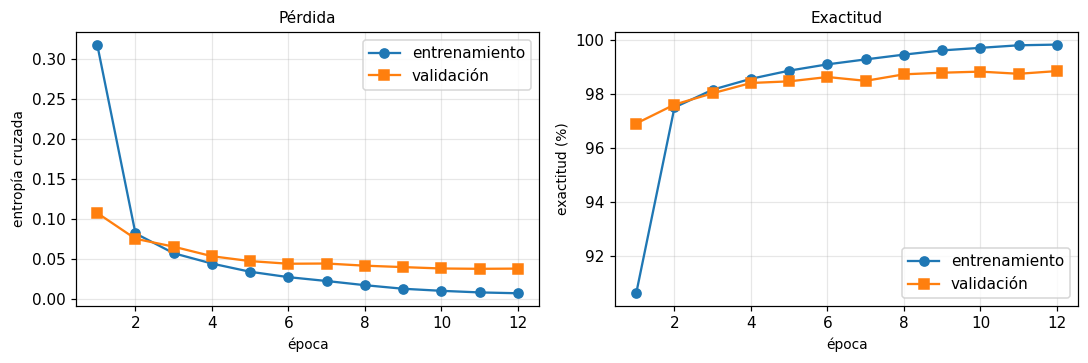

In [13]:
ep = np.arange(1, EPOCHS + 1)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(ep, history["train_loss"], "o-", label="entrenamiento")
a1.plot(ep, history["val_loss"], "s-", label="validación")
a1.set_xlabel("época"); a1.set_ylabel("entropía cruzada"); a1.set_title("Pérdida"); a1.legend(); a1.grid(alpha=.3)
a2.plot(ep, np.array(history["train_acc"]) * 100, "o-", label="entrenamiento")
a2.plot(ep, np.array(history["val_acc"]) * 100, "s-", label="validación")
a2.set_xlabel("época"); a2.set_ylabel("exactitud (%)"); a2.set_title("Exactitud"); a2.legend(); a2.grid(alpha=.3)
plt.tight_layout()
plt.show()

## 7. Evaluación en el conjunto de prueba

El conjunto de prueba no se usó en ningún momento del entrenamiento. La matriz de confusión cuenta, para cada dígito real (fila), cuántas veces la red predijo cada clase (columna). La diagonal son los aciertos.

Prueba: pérdida 0.0289  exactitud 99.05 %  (95 errores de 10000)


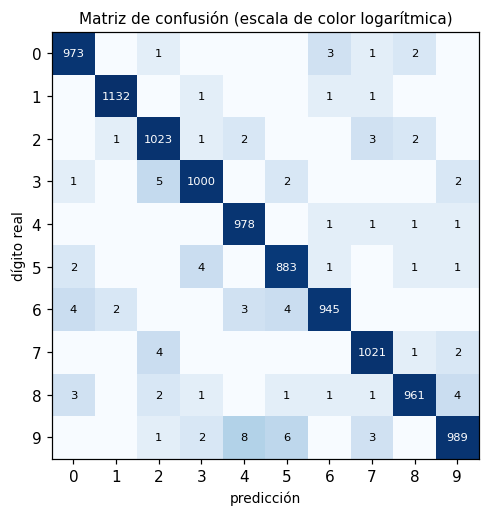

dígito 0: exactitud  99.29 %
dígito 1: exactitud  99.74 %
dígito 2: exactitud  99.13 %
dígito 3: exactitud  99.01 %
dígito 4: exactitud  99.59 %
dígito 5: exactitud  98.99 %
dígito 6: exactitud  98.64 %
dígito 7: exactitud  99.32 %
dígito 8: exactitud  98.67 %
dígito 9: exactitud  98.02 %


In [14]:
test_loss, test_acc = evaluate(test_loader)
print(f"Prueba: pérdida {test_loss:.4f}  exactitud {test_acc * 100:.2f} %  "
      f"({round((1 - test_acc) * len(test_set))} errores de {len(test_set)})")

model.eval()
all_pred, all_true, all_prob = [], [], []
with torch.no_grad():
    for x, y in test_loader:
        logits = model(x.to(DEVICE))
        all_prob.append(F.softmax(logits, 1).cpu())
        all_pred.append(logits.argmax(1).cpu())
        all_true.append(y)
all_pred = torch.cat(all_pred); all_true = torch.cat(all_true); all_prob = torch.cat(all_prob)

cm = torch.zeros(10, 10, dtype=torch.long)
for t, p in zip(all_true, all_pred):
    cm[t, p] += 1

fig, ax = plt.subplots(figsize=(5.6, 4.8))
im = ax.imshow(np.log1p(cm.numpy()), cmap="Blues")
for (r, c), v in np.ndenumerate(cm.numpy()):
    if v:
        ax.text(c, r, str(v), ha="center", va="center", fontsize=7.5, color="white" if r == c else "black")
ax.set_xticks(range(10)); ax.set_yticks(range(10))
ax.set_xlabel("predicción"); ax.set_ylabel("dígito real")
ax.set_title("Matriz de confusión (escala de color logarítmica)")
plt.tight_layout()
plt.show()

por_clase = cm.diag().float() / cm.sum(1).float()
for d in range(10):
    print(f"dígito {d}: exactitud {por_clase[d] * 100:6.2f} %")

## 8. Los kernels aprendidos

### C1: seis kernels de $5\times5\times1$

Cada kernel es una pequeña plantilla de pesos. Rojo significa peso positivo (el kernel "quiere" tinta en ese píxel) y azul negativo (el kernel "quiere" fondo). Arriba están los kernels de la inicialización aleatoria; abajo, los mismos después de entrenar. El entrenamiento los convierte en detectores de bordes y trazos con una orientación definida: una franja roja junto a una azul es un detector de borde perpendicular a esa franja.

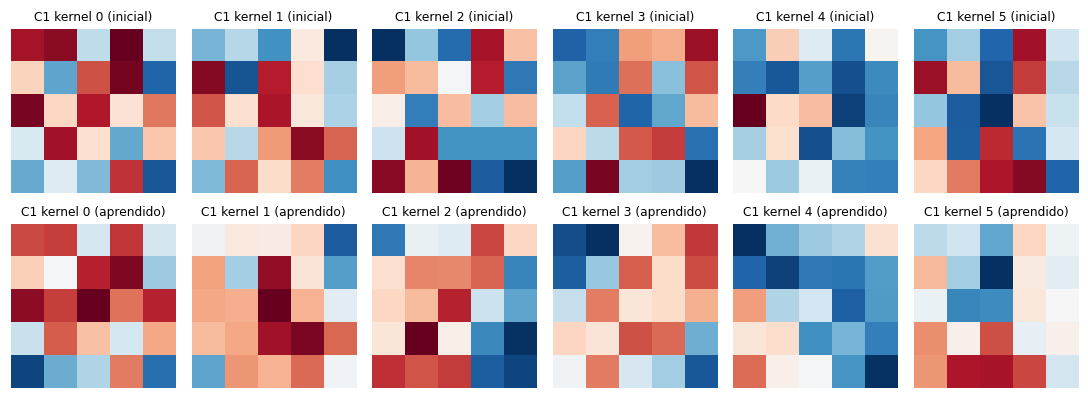

Pesos del kernel 0 aprendido (redondeados):
[[ 0.18  0.19 -0.04  0.19 -0.05]
 [ 0.06 -0.    0.21  0.25 -0.1 ]
 [ 0.24  0.19  0.27  0.15  0.21]
 [-0.06  0.16  0.08 -0.05  0.1 ]
 [-0.25 -0.13 -0.08  0.14 -0.2 ]]
sesgo: 0.2


In [15]:
c1_final = model.c1.weight.detach().cpu()
fig, axes = plt.subplots(2, 6, figsize=(10, 3.8))
for row, (W, nombre) in enumerate([(c1_inicial, "inicial"), (c1_final, "aprendido")]):
    for i in range(6):
        k = W[i, 0].numpy()
        m = np.abs(k).max()
        axes[row, i].imshow(k, cmap="RdBu_r", vmin=-m, vmax=m)
        axes[row, i].set_title(f"C1 kernel {i} ({nombre})", fontsize=8)
        axes[row, i].axis("off")
plt.tight_layout()
plt.show()

print("Pesos del kernel 0 aprendido (redondeados):")
print(np.round(c1_final[0, 0].numpy(), 2))
print("sesgo:", round(model.c1.bias[0].item(), 3))

### Efecto de cada kernel de C1 sobre un dígito

Aplicamos los seis kernels aprendidos a un dígito de prueba. La convolución la calculamos **dos veces**: con nuestra función manual de NumPy (la misma de la sección 3) y con la capa de PyTorch. Deben coincidir. Después de la convolución aplicamos ReLU, que deja pasar solo las respuestas positivas.

¿Conv manual == nn.Conv2d? True | diferencia máxima: 1.430511474609375e-06


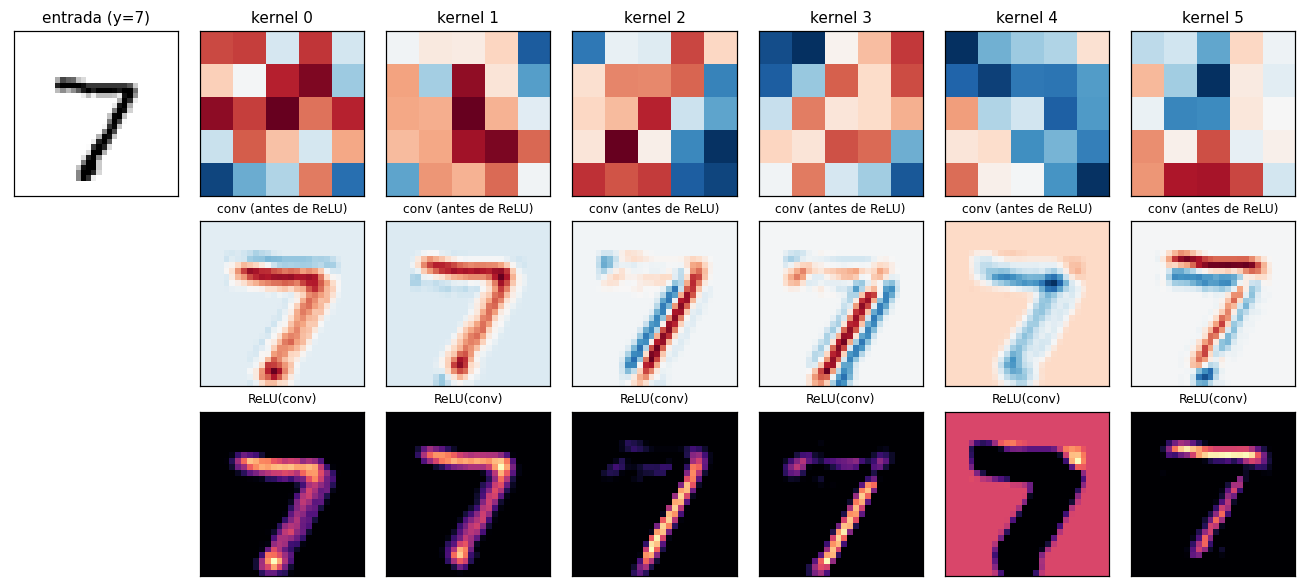

In [16]:
IDX = 0  # índice del dígito de ejemplo en el conjunto de prueba (es un 7)
x_ej, y_ej = test_set[IDX]
img = x_ej[0].numpy()

manual = np.stack([conv2d_manual(img, c1_final[i, 0].numpy(), model.c1.bias[i].item()) for i in range(6)])
with torch.no_grad():
    torch_c1 = model.c1(x_ej[None].to(DEVICE)).squeeze(0).cpu().numpy()
print("¿Conv manual == nn.Conv2d?", np.allclose(manual, torch_c1, atol=1e-4),
      "| diferencia máxima:", float(np.abs(manual - torch_c1).max()))

fig, axes = plt.subplots(3, 7, figsize=(12, 5.4))
axes[0, 0].imshow(to_img(x_ej), cmap="gray_r"); axes[0, 0].set_title(f"entrada (y={y_ej})")
for r in range(1, 3):
    axes[r, 0].axis("off")
for i in range(6):
    k = c1_final[i, 0].numpy(); m = np.abs(k).max()
    axes[0, i + 1].imshow(k, cmap="RdBu_r", vmin=-m, vmax=m); axes[0, i + 1].set_title(f"kernel {i}")
    axes[1, i + 1].imshow(manual[i], cmap="RdBu_r", vmin=-np.abs(manual[i]).max(), vmax=np.abs(manual[i]).max())
    axes[1, i + 1].set_title("conv (antes de ReLU)", fontsize=8)
    axes[2, i + 1].imshow(np.maximum(manual[i], 0), cmap="magma"); axes[2, i + 1].set_title("ReLU(conv)", fontsize=8)
for ax in axes.flat:
    ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout()
plt.show()

### C3: dieciséis kernels de $6\times5\times5$

Cada kernel de C3 tiene una lámina de $5\times5$ por cada uno de los 6 mapas de S2. La figura muestra la matriz completa: fila = kernel de C3 (mapa de salida), columna = canal de entrada. La tabla de normas al final mide cuánto usa cada kernel cada canal: con conexión completa, cada kernel combina los seis canales con pesos distintos y suele apoyarse más en dos o tres de ellos. El LeNet original imponía esa selectividad con una tabla fija de conexiones parciales; aquí la decide el entrenamiento.

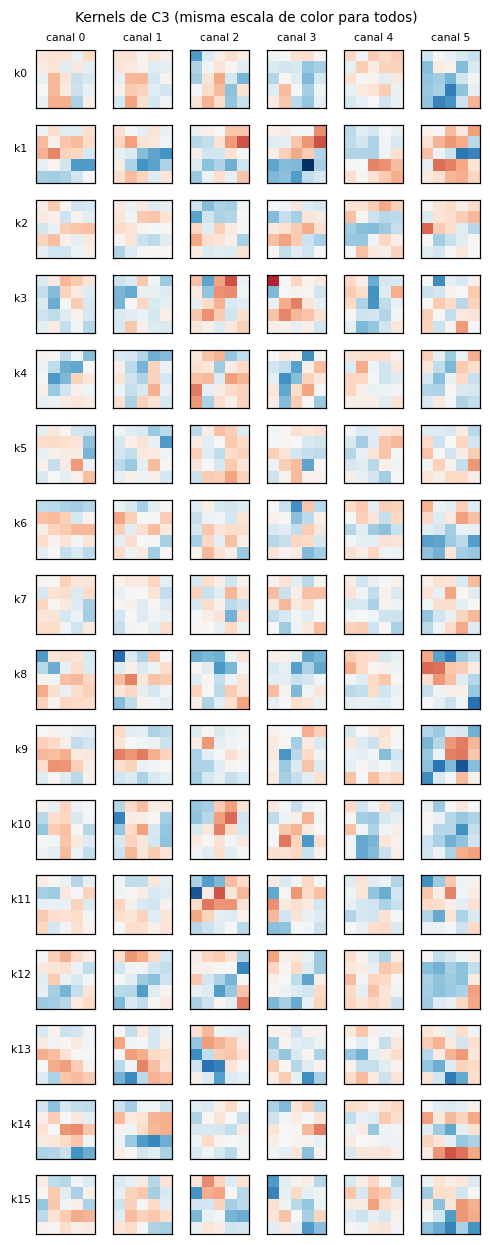

Norma L1 por (kernel, canal), normalizada por fila:
[[0.55 0.51 0.75 0.63 0.46 1.  ]
 [0.73 0.74 0.69 1.   0.62 0.9 ]
 [0.63 0.51 0.87 0.83 1.   0.72]
 [0.74 0.72 1.   0.79 0.96 0.68]
 [0.76 0.91 1.   0.99 0.53 0.85]
 [0.83 0.86 1.   0.78 0.83 0.85]
 [0.74 0.56 0.61 0.77 0.63 1.  ]
 [0.86 0.54 0.89 0.92 0.77 1.  ]
 [0.71 0.7  0.74 0.67 0.49 1.  ]
 [0.47 0.53 0.38 0.48 0.34 1.  ]
 [0.63 0.98 0.89 0.71 0.84 1.  ]
 [0.49 0.42 1.   0.66 0.6  0.66]
 [0.67 0.76 0.8  0.72 0.56 1.  ]
 [0.63 0.87 1.   0.65 0.58 0.91]
 [0.92 0.94 0.48 0.6  0.48 1.  ]
 [0.63 0.68 0.88 0.77 0.54 1.  ]]


In [17]:
W3 = model.c3.weight.detach().cpu().numpy()  # (16, 6, 5, 5)
m = np.abs(W3).max()
fig, axes = plt.subplots(16, 6, figsize=(4.6, 11.5))
for o in range(16):
    for c in range(6):
        axes[o, c].imshow(W3[o, c], cmap="RdBu_r", vmin=-m, vmax=m)
        axes[o, c].set_xticks([]); axes[o, c].set_yticks([])
        if o == 0:
            axes[o, c].set_title(f"canal {c}", fontsize=7)
        if c == 0:
            axes[o, c].set_ylabel(f"k{o}", fontsize=7, rotation=0, labelpad=10)
fig.suptitle("Kernels de C3 (misma escala de color para todos)", fontsize=9)
plt.tight_layout()
plt.show()

uso = np.abs(W3).sum(axis=(2, 3))
print("Norma L1 por (kernel, canal), normalizada por fila:")
print(np.round(uso / uso.max(axis=1, keepdims=True), 2))

## 9. La red "capas adentro"

Ahora seguimos al mismo dígito por toda la red y miramos lo que ve cada capa:

- **C1** ($6\times28\times28$): rasgos de bajo nivel. Cada mapa resalta los trazos con una orientación.
- **S2** ($6\times14\times14$): los mismos mapas a media resolución.
- **C3** ($16\times10\times10$): combinaciones de los 6 rasgos anteriores. Responden a esquinas, cruces y curvas, y ya se parecen poco al dígito.
- **S4** ($16\times5\times5$): 400 números que resumen *qué rasgos aparecen y en qué región aproximada*.
- **F5** y **F6**: vectores de 120 y 84 números; cada neurona combina rasgos de toda la imagen.
- **Salida**: probabilidades de las 10 clases.

Al avanzar, la representación pierde resolución espacial y gana número de canales: la red cambia "dónde" por "qué".

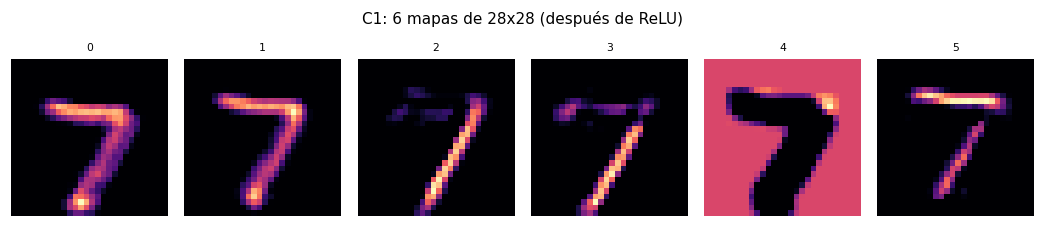

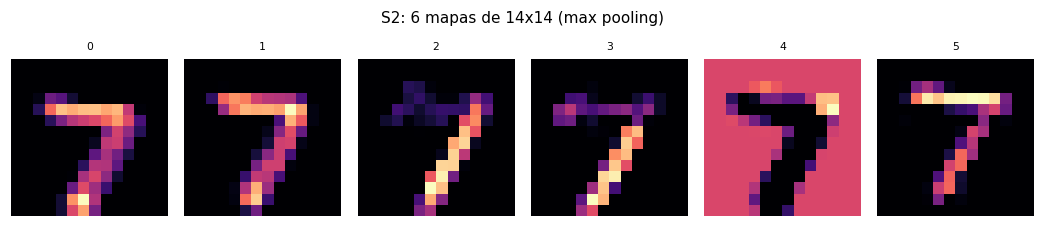

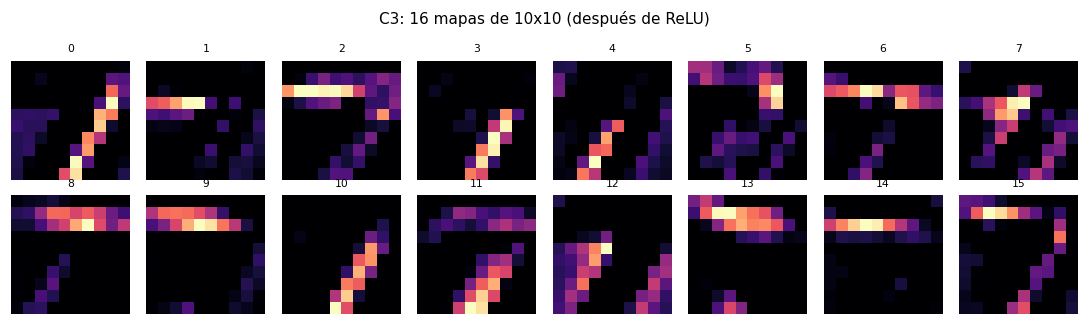

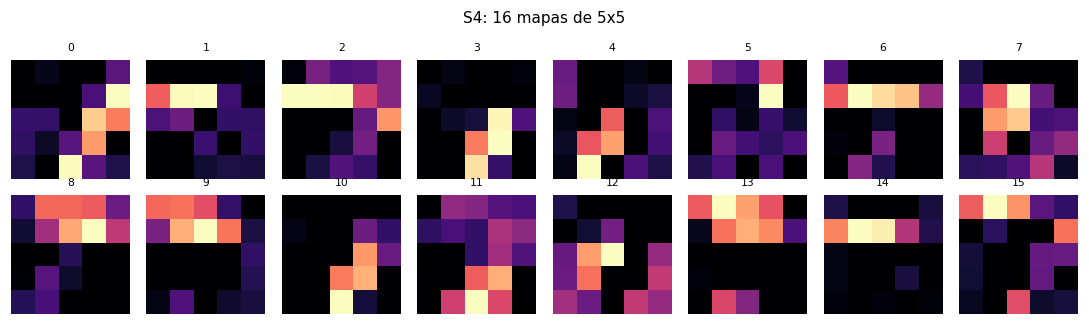

In [18]:
model.eval()
with torch.no_grad():
    logits, A = model(x_ej[None].to(DEVICE), keep=True)
probs = F.softmax(logits, 1).squeeze().cpu().numpy()
A = {k: v.squeeze(0).cpu().numpy() for k, v in A.items()}


def show_maps(maps, titulo, cols, cmap="magma", size=1.25):
    n = maps.shape[0]
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * size, rows * size + 0.5))
    for i, ax in enumerate(np.atleast_1d(axes).flat):
        ax.axis("off")
        if i < n:
            ax.imshow(maps[i], cmap=cmap)
            ax.set_title(str(i), fontsize=7)
    fig.suptitle(titulo, fontsize=10)
    plt.tight_layout()
    plt.show()


show_maps(A["c1"], "C1: 6 mapas de 28x28 (después de ReLU)", 6, size=1.6)
show_maps(A["s2"], "S2: 6 mapas de 14x14 (max pooling)", 6, size=1.6)
show_maps(A["c3"], "C3: 16 mapas de 10x10 (después de ReLU)", 8)
show_maps(A["s4"], "S4: 16 mapas de 5x5", 8)

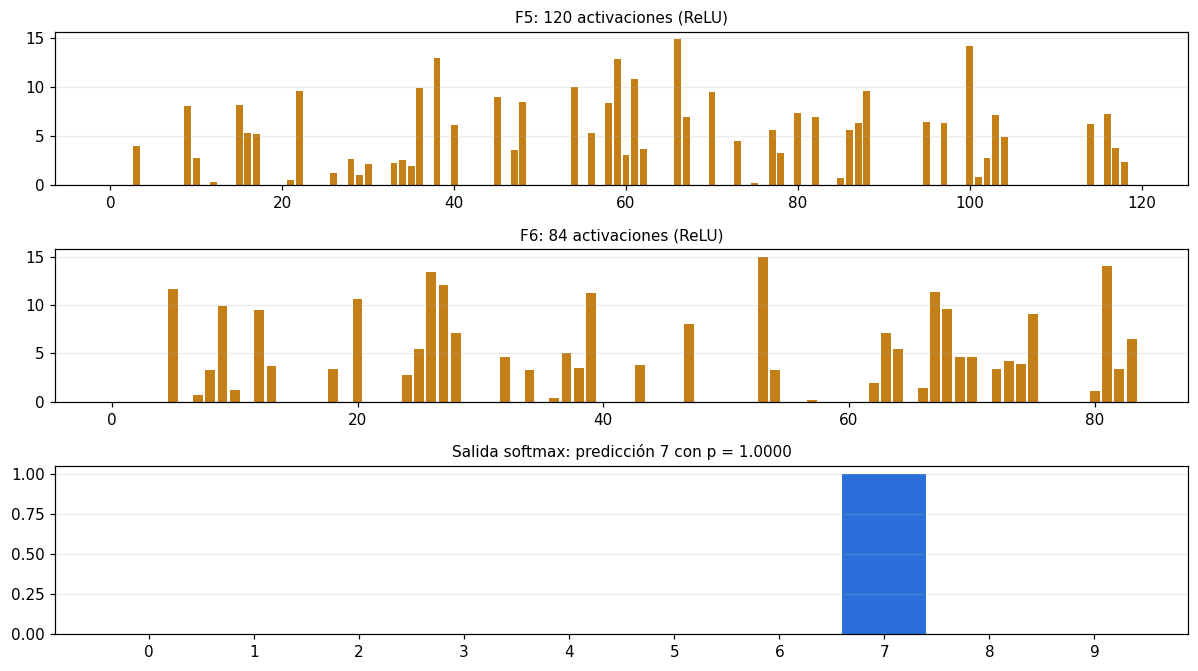

Neuronas activas (> 0): F5 53/120   F6 41/84


In [19]:
fig, axes = plt.subplots(3, 1, figsize=(11, 6.2), gridspec_kw={"height_ratios": [1, 1, 1.1]})
axes[0].bar(range(120), A["f5"], color="#c47f17"); axes[0].set_title("F5: 120 activaciones (ReLU)")
axes[1].bar(range(84), A["f6"], color="#c47f17"); axes[1].set_title("F6: 84 activaciones (ReLU)")
colores = ["#2a6fdb" if d == probs.argmax() else "#9aa4b2" for d in range(10)]
axes[2].bar(range(10), probs, color=colores); axes[2].set_xticks(range(10))
axes[2].set_title(f"Salida softmax: predicción {probs.argmax()} con p = {probs.max():.4f}")
for ax in axes:
    ax.grid(alpha=.25, axis="y")
plt.tight_layout()
plt.show()

print(f"Neuronas activas (> 0): F5 {np.sum(A['f5'] > 0)}/120   F6 {np.sum(A['f6'] > 0)}/84")

### ¿Qué píxeles decidieron la clase?

Un **mapa de saliencia** mide cuánto cambia la puntuación de la clase predicha si alteramos ligeramente cada píxel: es el valor absoluto del gradiente $\left|\partial z_{\hat y} / \partial x_{i,j}\right|$, que se obtiene con una sola pasada de backpropagation hasta la imagen. Muestra en qué zonas del dígito se apoya la red.

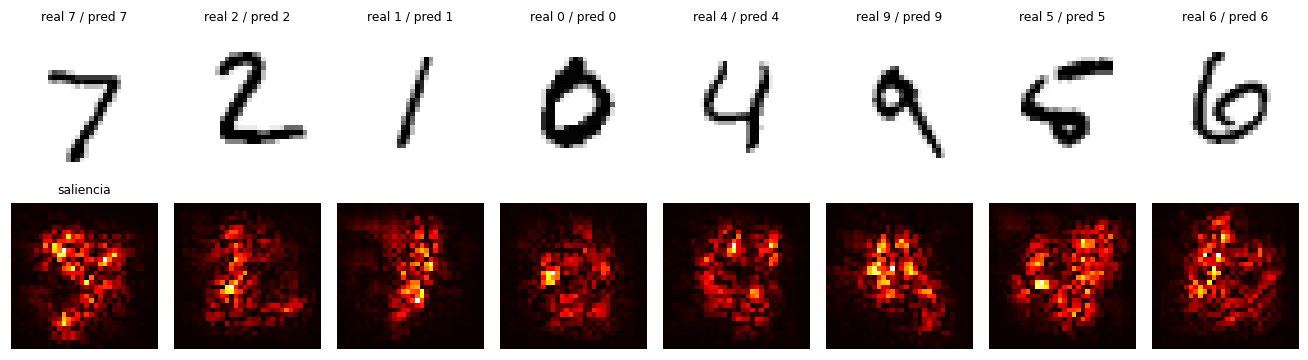

In [20]:
def saliency(x):
    x = x[None].to(DEVICE).requires_grad_(True)
    logits = model(x)
    c = logits.argmax(1).item()
    logits[0, c].backward()
    return x.grad.abs().squeeze().cpu().numpy(), c


fig, axes = plt.subplots(2, 8, figsize=(12, 3.4))
for j, idx in enumerate([0, 1, 2, 3, 4, 7, 8, 11]):
    x, y = test_set[idx]
    s, c = saliency(x)
    axes[0, j].imshow(to_img(x), cmap="gray_r"); axes[0, j].set_title(f"real {y} / pred {c}", fontsize=8)
    axes[1, j].imshow(s, cmap="hot")
    axes[0, j].axis("off"); axes[1, j].axis("off")
axes[1, 0].set_title("saliencia", fontsize=8)
plt.tight_layout()
plt.show()

## 10. Ejemplos inferidos con la red entrenada

Tomamos 40 dígitos de prueba elegidos al azar (semilla fija) y mostramos la predicción con su probabilidad. Verde es acierto y rojo error.

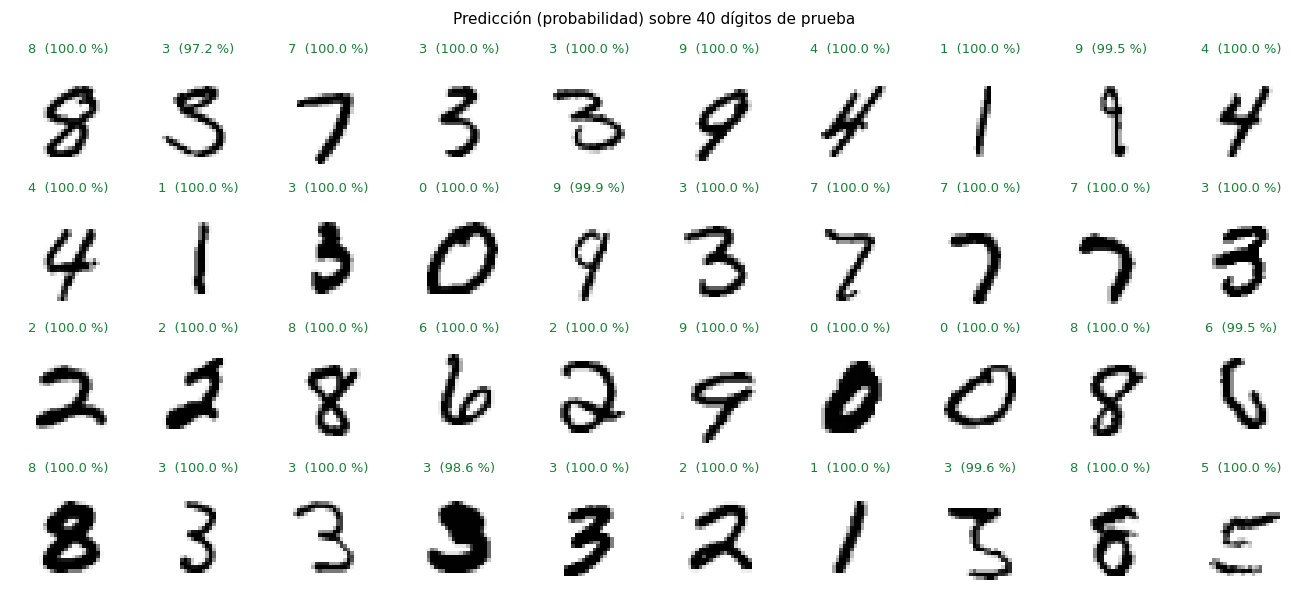

Aciertos en la muestra: 40 de 40


In [21]:
rng = np.random.default_rng(SEED)
muestra = rng.choice(len(test_set), size=40, replace=False)

fig, axes = plt.subplots(4, 10, figsize=(12, 5.6))
for ax, idx in zip(axes.flat, muestra):
    x, y = test_set[idx]
    p = all_prob[idx]
    c = int(p.argmax())
    ax.imshow(to_img(x), cmap="gray_r")
    ax.set_title(f"{c}  ({p[c] * 100:.1f} %)", fontsize=8.5, color="#1a7f37" if c == y else "#cf222e")
    ax.axis("off")
fig.suptitle("Predicción (probabilidad) sobre 40 dígitos de prueba", fontsize=10)
plt.tight_layout()
plt.show()
print("Aciertos en la muestra:", int((all_pred[muestra] == all_true[muestra]).sum()), "de 40")

### Distribución completa de probabilidades

Para seis ejemplos mostramos la imagen junto a las diez probabilidades. En los aciertos claros casi toda la masa queda en una clase; en los dígitos ambiguos se reparte entre dos o tres.

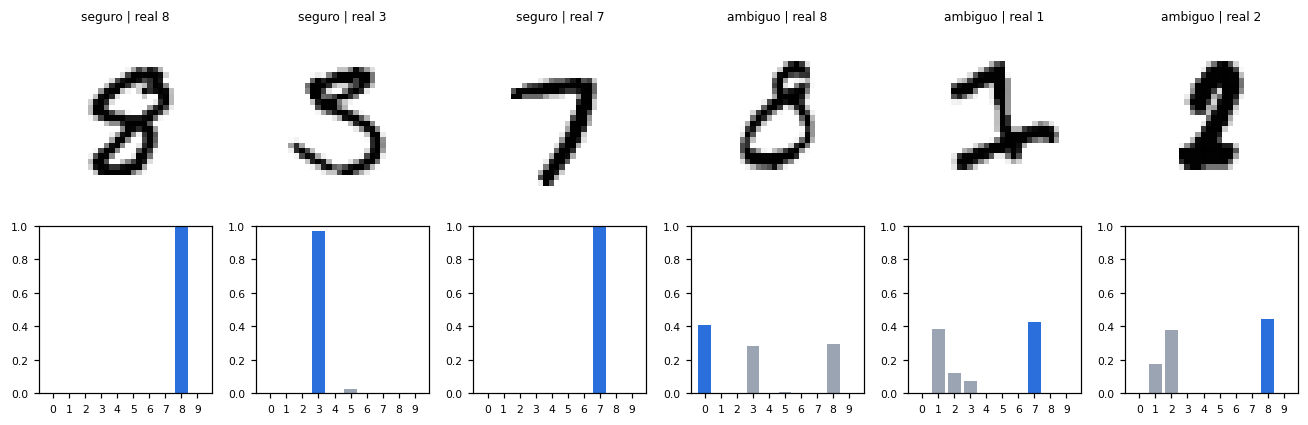

In [22]:
conf = all_prob.max(1).values
ambiguos = torch.argsort(conf)[:3].tolist()
seguros = [int(i) for i in muestra[:3]]
fig, axes = plt.subplots(2, 6, figsize=(12, 4), gridspec_kw={"height_ratios": [1.2, 1]})
for j, idx in enumerate(seguros + ambiguos):
    x, y = test_set[idx]
    p = all_prob[idx].numpy()
    axes[0, j].imshow(to_img(x), cmap="gray_r"); axes[0, j].axis("off")
    axes[0, j].set_title(("seguro" if j < 3 else "ambiguo") + f" | real {y}", fontsize=8)
    axes[1, j].bar(range(10), p, color=["#2a6fdb" if d == p.argmax() else "#9aa4b2" for d in range(10)])
    axes[1, j].set_xticks(range(10)); axes[1, j].set_ylim(0, 1); axes[1, j].tick_params(labelsize=7)
plt.tight_layout()
plt.show()

### Los errores

Estos son los dígitos de prueba mal clasificados con mayor confianza. Conviene discutirlos en clase: muchos son ambiguos incluso para una persona, y otros revelan los límites de una red pequeña sin aumento de datos.

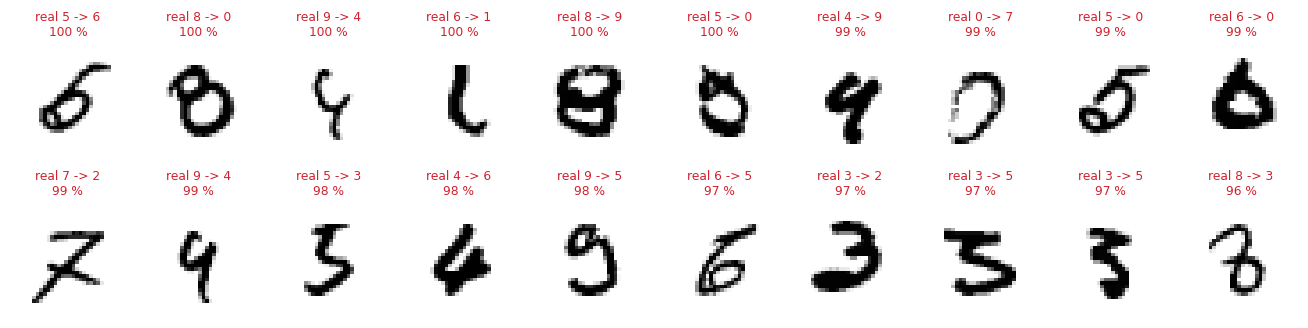

Total de errores: 95


In [23]:
errores = torch.nonzero(all_pred != all_true).squeeze(1)
orden = errores[torch.argsort(all_prob[errores].max(1).values, descending=True)]
n_show = min(20, len(orden))
fig, axes = plt.subplots(2, 10, figsize=(12, 3.2))
for ax in axes.flat:
    ax.axis("off")
for ax, idx in zip(axes.flat, orden[:n_show].tolist()):
    x, y = test_set[idx]
    p = all_prob[idx]
    ax.imshow(to_img(x), cmap="gray_r")
    ax.set_title(f"real {y} -> {int(p.argmax())}\n{p.max() * 100:.0f} %", fontsize=8, color="#cf222e")
plt.tight_layout()
plt.show()
print("Total de errores:", len(errores))

## 11. Exportar el modelo y los datos del diagrama

Guardamos los pesos entrenados en `results/lenet/` (carpeta ignorada por git) y exportamos a `figures/lenet/anatomy_data.json` lo que el diagrama isométrico graba sobre sus piezas: el dígito de ejemplo, las activaciones de cada capa, los kernels y las matrices de F5, F6 y salida promediadas por bloques. El diagrama se reconstruye con

```bash
node scripts/anatomy_lenet/build.mjs
```

In [24]:
torch.save({"state_dict": model.state_dict(), "test_acc": test_acc, "history": history},
           OUT_DIR / "lenet5_mnist.pt")


def block_mean(W, rows, cols):
    R, C = W.shape
    return W.reshape(rows, R // rows, cols, C // cols).mean(axis=(1, 3))


r3 = lambda a: np.round(np.asarray(a, dtype=np.float64), 3).tolist()
sd = {k: v.detach().cpu().numpy() for k, v in model.state_dict().items()}
anatomy = {
    "index": IDX,
    "label": int(y_ej),
    "pred": int(probs.argmax()),
    "probs": r3(probs),
    "test_acc": round(test_acc, 4),
    "params": {n: int(p.numel()) for n, p in model.named_parameters()},
    "input": r3(to_img(x_ej)),
    "c1": r3(A["c1"]), "s2": r3(A["s2"]), "c3": r3(A["c3"]), "s4": r3(A["s4"]),
    "f5": r3(A["f5"]), "f6": r3(A["f6"]),
    "k1": r3(sd["c1.weight"][:, 0]),
    "k3": r3(sd["c3.weight"]),
    "w5": r3(block_mean(sd["f5.weight"], 24, 40)),
    "w6": r3(block_mean(sd["f6.weight"], 21, 30)),
    "w7": r3(block_mean(sd["out.weight"], 10, 21)),
}
(FIG_DIR / "anatomy_data.json").write_text(json.dumps(anatomy, separators=(",", ":")))
print("guardado:", OUT_DIR / "lenet5_mnist.pt")
print("guardado:", FIG_DIR / "anatomy_data.json", f"({(FIG_DIR / 'anatomy_data.json').stat().st_size / 1024:.0f} KB)")
print(f"exactitud en prueba: {test_acc * 100:.2f} %   |   predicción del ejemplo: {anatomy['pred']} (real {anatomy['label']})")

guardado: /workspace/friendly-fiesta/results/lenet/lenet5_mnist.pt
guardado: /workspace/friendly-fiesta/figures/lenet/anatomy_data.json (71 KB)
exactitud en prueba: 99.05 %   |   predicción del ejemplo: 7 (real 7)
